### Importando Bibliotecas

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.fft import fft, fftshift, fftfreq

sample_rate = 25_000_000
bytes_per_sample = 4
n_points = 1_000_000
INT16_MAX = 32768.0

### Carregando Dados

In [46]:
def signal_analyze(filename):

    # load data
    filesize = os.path.getsize(filename)
    n_int16 = filesize // 2  # num de int16 que existem no arquivo
    total_samples = filesize // bytes_per_sample
    print(f"Arquivo: {filename}, bytes={filesize:,}, amostras={total_samples:,}")
    # Cria 100.000 números uniformemente espaçados entre 0 e total_samples - 1 
    sample_indices = np.linspace(0, total_samples - 1, num=n_points, dtype=np.int64)
    
    # Cria um acesso direto ao arquivo binário
    mm = np.memmap(filename, dtype=np.int16, mode="r", shape=(n_int16,))
    
    idx_I = 2 * sample_indices
    idx_Q = idx_I + 1

    # podemos normalizar o sinal
    I = mm[idx_I].astype(np.float32) / INT16_MAX
    Q = mm[idx_Q].astype(np.float32) / INT16_MAX

    iq = I + 1j * Q
    time_axis = sample_indices / sample_rate # pega o segundo de cada amostra

    # Signal Power
    power_db = 10 * np.log10(I**2 + Q**2 + 1e-12)
    print(power_db)

    # Usa uma janela deslizante simples (média móvel)
    window_size = 500       # ajustável — quanto maior, mais suave
    kernel = np.ones(window_size) / window_size
    smooth_power_db = np.convolve(power_db, kernel, mode='same')

    plt.figure(figsize=(12,5))
    plt.plot(time_axis, power_db, '.', color='lightgray', markersize=2, label='Potência instantânea')
    plt.plot(time_axis, smooth_power_db, color='blue', linewidth=1.5, label=f'Potência suavizada (janela={window_size})')
    plt.axvline(120, color='r', linestyle='--', label='Início esperado do spoofing (~120s)')
    plt.title(f"Potência instantânea e suavizada — {n_points} amostras espaçadas")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Potência (dB)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    
    base = os.path.basename(filename)
    base_no_ext = os.path.splitext(base)[0]
    out_path = f"Imagens/{base_no_ext}_power_plot.png"

    plt.savefig(out_path, dpi=300)
    plt.show()
    plt.close()

    # Doppler 
    print("Doppler aproximados")
    win = 2000
    step = 2000
    times_cn0, cn0, doppler = [], [], []
    for i in range(0, len(iq)-win, step):
        seg = iq[i:i+win] * np.hanning(win)
        S = np.abs(fftshift(fft(seg)))**2
        f = fftshift(fftfreq(win, 1/sample_rate))
        sig = S[np.abs(f) < 1e6].sum()
        noise = S[(np.abs(f) > 2e6) & (np.abs(f) < 10e6)].mean()
        cn0.append(10*np.log10(sig/(noise+1e-15)))
        doppler.append(f[np.argmax(S)])
        times_cn0.append(time_axis[i])

    plt.figure(figsize=(10,3))
    plt.plot(times_cn0, doppler)
    plt.title("Doppler estimado (Hz)")
    plt.xlabel("Tempo (s)"); plt.ylabel("Hz")
    plt.grid(True); plt.tight_layout()
    plt.show()

    print("Calculando proxy de C/N0 baseado na potência...")

    window_size_cn0 = 1000
    kernel_cn0 = np.ones(window_size_cn0) / window_size_cn0
    smooth_power_cn0 = np.convolve(power_db, kernel_cn0, mode='same')
    cn0_proxy = smooth_power_cn0 - np.min(smooth_power_cn0)

    plt.figure(figsize=(10,3))
    plt.plot(time_axis, cn0_proxy, color='purple', linewidth=1.5)
    plt.axvline(120, color='r', linestyle='--', label='Início esperado do spoofing (~120s)')
    plt.title("Proxy simples de C/N₀ (baseado na potência suavizada)")
    plt.xlabel("Tempo (s)")
    plt.ylabel("C/N₀ relativo (dB)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    # Salva o gráfico
    base = os.path.basename(filename)
    base_no_ext = os.path.splitext(base)[0]
    out_path_cn0 = f"Imagens/{base_no_ext}_cn0_proxy.png"
    plt.savefig(out_path_cn0, dpi=300)
    plt.show()
    plt.close()

    print("Gerando constelações I/Q...")
    def plot_constellation(iq, title):
        plt.scatter(np.real(iq[::10]), np.imag(iq[::10]), s=2)
        plt.axis("equal"); plt.xlabel("I"); plt.ylabel("Q")
        plt.title(title); plt.grid(True)

    mid = len(iq)//2
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plot_constellation(iq[:mid], "Antes do spoofing")
    plt.subplot(1,2,2)
    plot_constellation(iq[mid:], "Depois do spoofing")
    plt.tight_layout(); plt.show()

    def plot_constellation(iq_segment, title):
        plt.scatter(np.real(iq_segment[::10]), np.imag(iq_segment[::10]), s=2)
        plt.axis("equal")
        plt.xlabel("I")
        plt.ylabel("Q")
        plt.title(title)
        plt.grid(True)

    # --- Define o tempo de início esperado do spoofing (120 s)
    spoof_start = 120  

    # Escolhe amostras antes e depois do ataque
    before_mask = time_axis < spoof_start
    after_mask  = time_axis >= spoof_start

    # Cria subconjuntos
    iq_before = iq[before_mask]
    iq_after  = iq[after_mask]

    # --- Plota lado a lado
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plot_constellation(iq_before, "Antes do spoofing (<120s)")
    plt.subplot(1,2,2)
    plot_constellation(iq_after, "Durante/Depois do spoofing (≥120s)")
    plt.tight_layout()
    plt.show()

    phase = np.unwrap(np.angle(iq))

    phase_diff = np.diff(phase)
    freq_inst = (sample_rate / (2 * np.pi)) * phase_diff

    plt.figure(figsize=(12,4))
    plt.plot(time_axis[1:], freq_inst, linewidth=0.5)
    plt.axvline(120, color='r', linestyle='--', label='Início do spoofing (~120s)')
    plt.title("Variação de fase (frequência instantânea)")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Hz (derivada de fase)")
    plt.legend(); plt.grid(True); plt.tight_layout()
    plt.show()

    print("Analisando fase do sinal ao longo do tempo...")

    # Calcula a fase instantânea (em radianos)
    phase = np.angle(iq)

    # "unwrap" remove saltos de 2π (mantém a fase contínua)
    phase_unwrapped = np.unwrap(phase)

    # Plota a fase ao longo do tempo
    plt.figure(figsize=(12,4))
    plt.plot(time_axis, phase_unwrapped, linewidth=0.6)
    plt.axvline(120, color='r', linestyle='--', label='Início esperado do spoofing (~120s)')
    plt.title("Fase instantânea do sinal ao longo do tempo")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Fase (radianos, contínua)")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    # Salvar gráfico
    base = os.path.basename(filename)
    base_no_ext = os.path.splitext(base)[0]
    out_path_phase = f"Imagens/{base_no_ext}_phase_plot.png"
    plt.savefig(out_path_phase, dpi=300)
    plt.show()
    plt.close()

    print("Gerando 'Phase Trauma Flag'...")

    # Pega os dados de frequência instantânea que você já calculou
    # (Temos que re-alinhar os eixos do tempo, pois np.diff reduz o tamanho)
    time_axis_diff = time_axis[1:]

    # --- ESTE É O PASSO-CHAVE ---
    # Definir um limiar. Você terá que "brincar" com este valor.
    # Olhe o seu gráfico de 'freq_inst' e veja qual o nível de ruído normal.
    # O trauma será um pico MUITO acima disso. 
    # Vou chutar um valor alto, ex: 10 kHz.
    trauma_threshold = 100000  # <--- AJUSTE ESTE VALOR (em Hz)

    # Cria o flag: 1 se o trauma for detectado, 0 caso contrário
    phase_trauma_flag = np.abs(freq_inst) > trauma_threshold

    # --- Plotar o novo gráfico (Flag) ---
    plt.figure(figsize=(12, 4))
    # Usamos '.astype(float)' para plotar 0s e 1s
    plt.plot(time_axis_diff, phase_trauma_flag.astype(float), 'b-', label='Phase Trauma Flag')
    plt.axvline(120, color='r', linestyle='--', label='Início do spoofing (~120s)')
    plt.title("Indicador de 'Phase Trauma' (Flag)")
    plt.xlabel("Tempo (s)")
    plt.ylabel("Flag")
    plt.ylim(-0.1, 1.1) # Para forçar o eixo Y a ficar entre 0 e 1
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    # Salvar o gráfico do flag
    base = os.path.basename(filename)
    base_no_ext = os.path.splitext(base)[0]
    out_path_trauma = f"Imagens/{base_no_ext}_trauma_flag_plot.png"
    plt.savefig(out_path_trauma, dpi=300)
    plt.show()
    plt.close()
    

## Análises

### Clean Signal

Arquivo: ../cleanStatic.bin, bytes=48,016,392,192, amostras=12,004,098,048
[54.488503 64.72167  67.478745 ... 66.0177   63.0337   67.74727 ]


C:\Users\ferna\AppData\Local\Temp\ipykernel_21172\518037709.py:43: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\ferna\AppData\Local\Temp\ipykernel_21172\518037709.py:49: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(out_path, dpi=300)
C:\Users\ferna\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


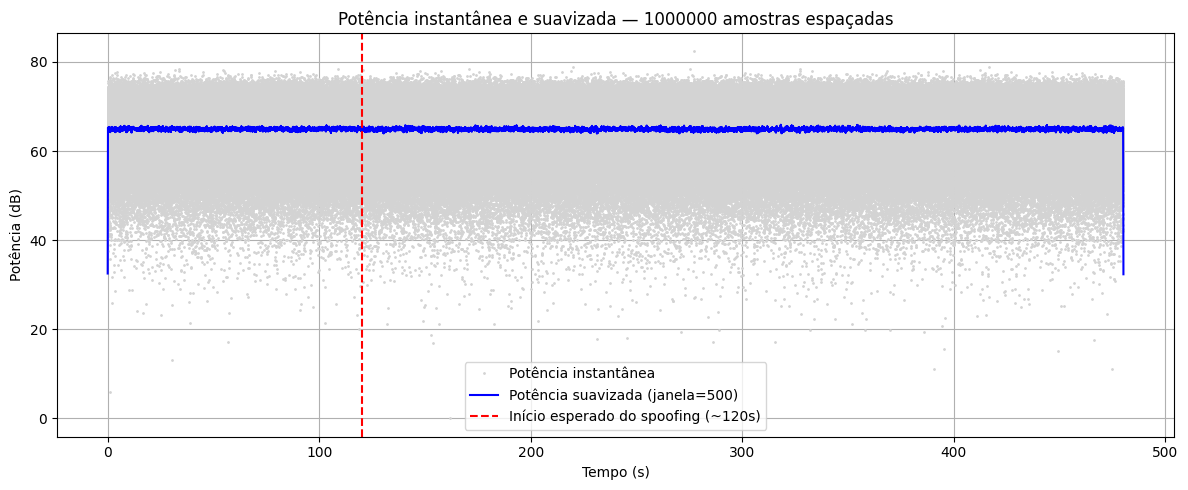

In [10]:
filename = '../cleanStatic.bin'

signal_analyze(filename)

### Spoofed Signal

Arquivo: ../ds2.bin, bytes=45,717,913,600, amostras=11,429,478,400
[-35.09311  -39.503563 -37.183907 ... -26.967981 -42.168655 -23.268776]


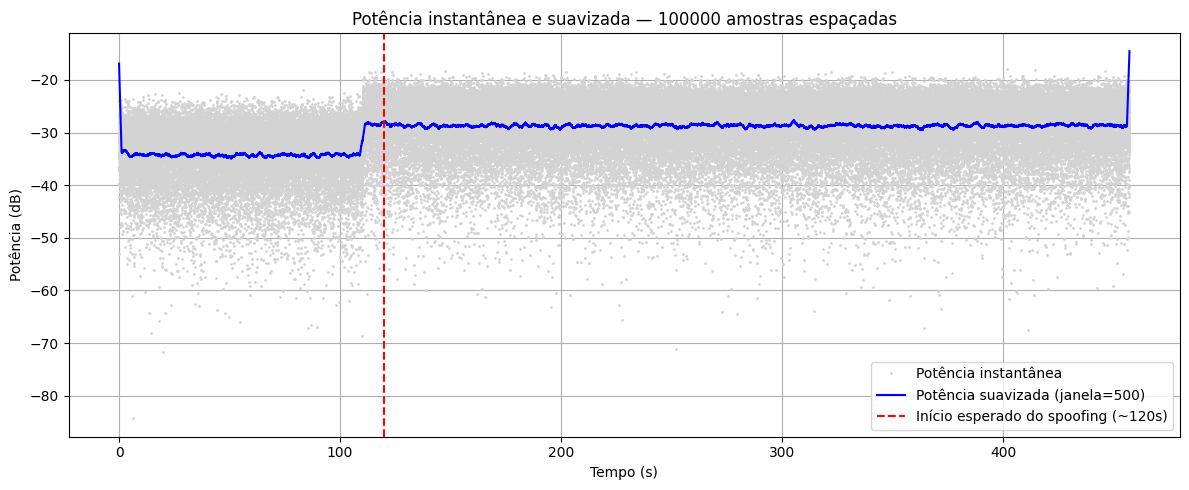

Doppler aproximados


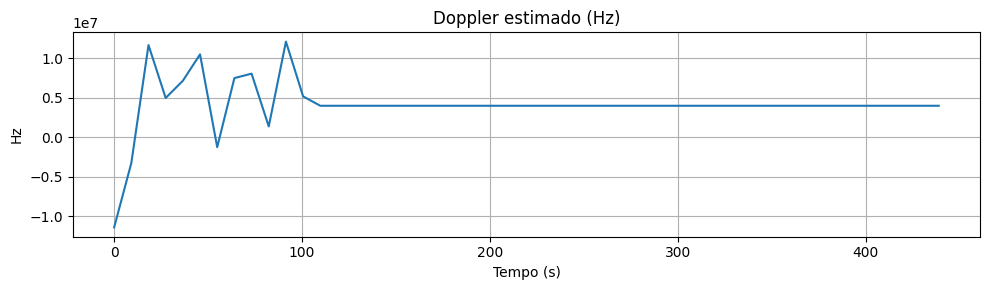

Calculando proxy de C/N0 baseado na potência...


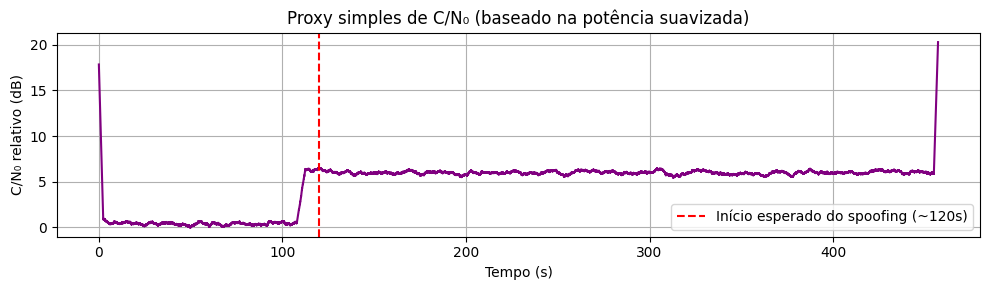

Gerando constelações I/Q...


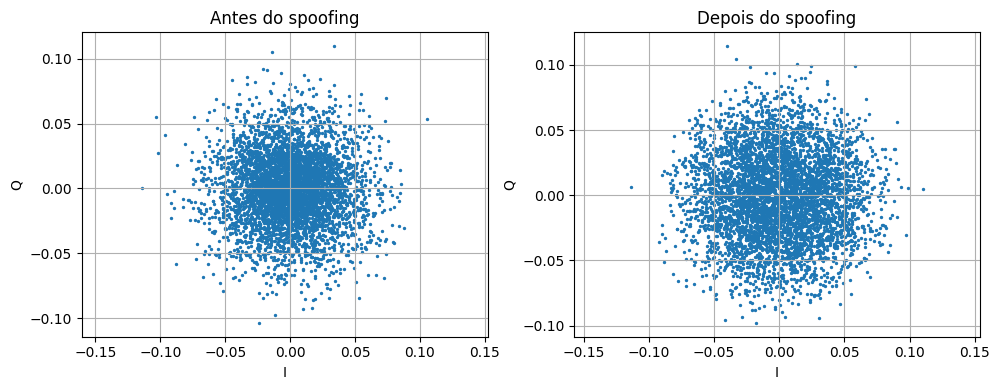

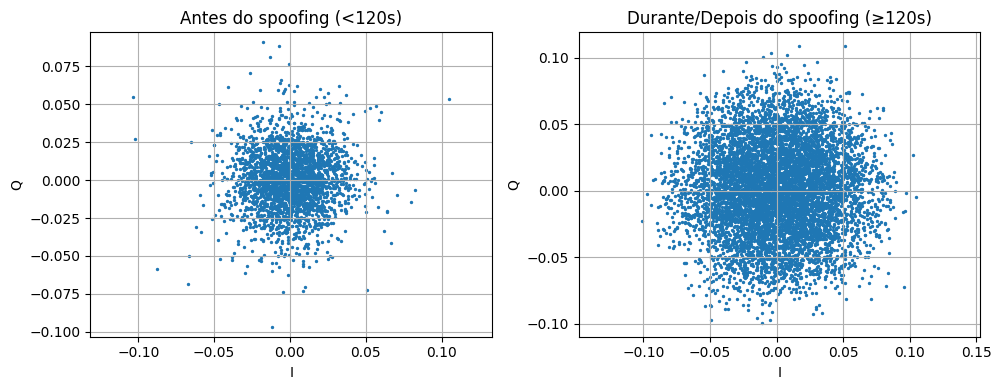

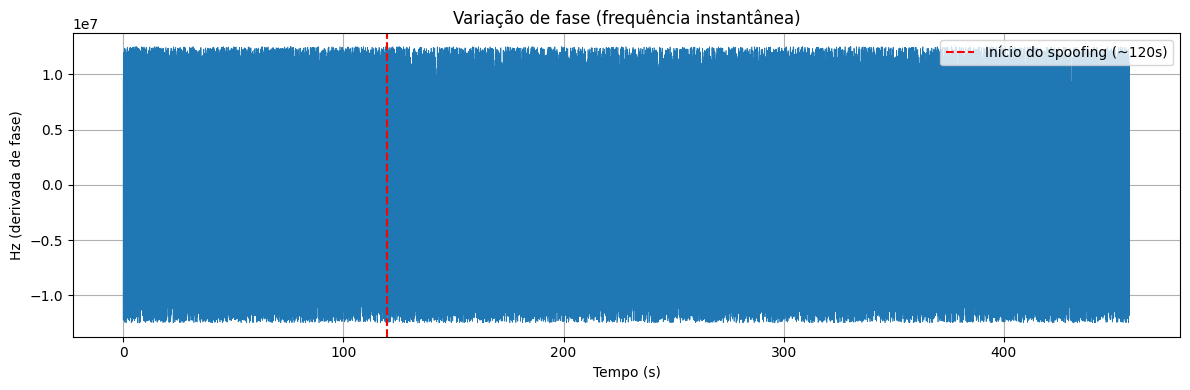

Analisando fase do sinal ao longo do tempo...


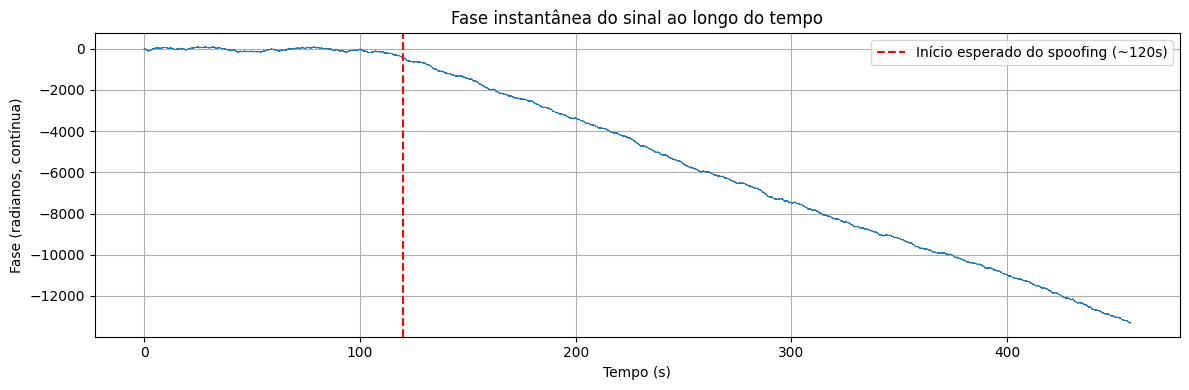

Gerando 'Phase Trauma Flag'...


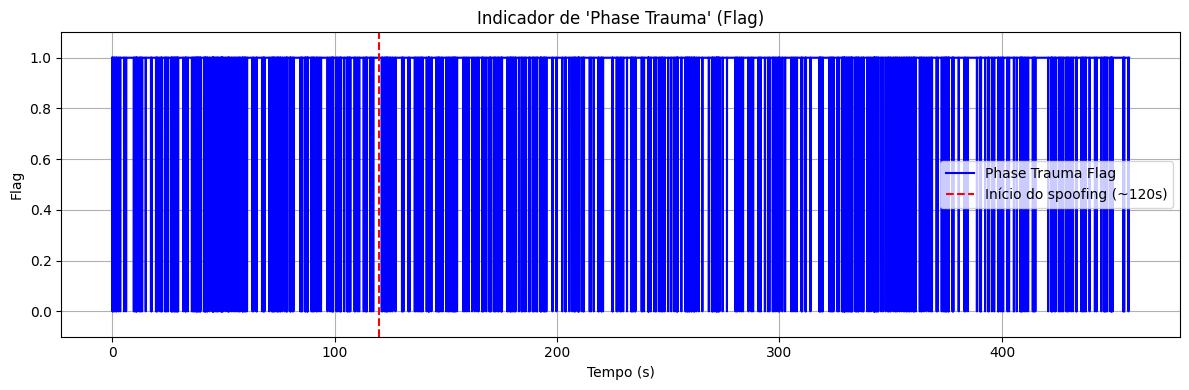

In [47]:
filename = '../ds2.bin'

signal_analyze(filename)